# Exercise 2 - Solving a Bungee Jump Differential Equation
**2889683m**

In [1]:
# Import the relevant data packages required for this exercise
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

## Aims

The aims of this exercise are as follows:
- Use a numerical approach to solve various differential equations
- Use library functions to solve these differential equations (`solve_ivp` from `SciPy`)
- Tackle these ODEs by building up more complicated functions out of simpler ones
- Investigate the behaviour of the solutions to these ODEs by varying the input variables and starting conditions

## Checking my Understanding

In order to check my understanding of how differential equations can be approximated by discretising the problem, the following differential equations are turned into difference equations:
1) $$ \frac{dZ}{dt} = -kZ^2 \text{ becomes } Z_{i+1} = Z_i(1 - kZ_i \Delta t) $$
2) $$ \frac{df}{dt} = \frac{1}{t} \text{ becomes } f_{i+1} = f_i(1 - \frac{\Delta t}{t_i}) $$
3) $$ a\frac{dy}{dt} + by + c = 0 \text{ becomes } y_{i+1} = y_i - \left(\frac{c+by_i}{a}\right) \Delta t $$

Small step sizes are important because difference equations approximate the instantaneous change of a differential equation with a finite jump.
A large jump assumes the derivative is constant over that interval, which is usually false. Two steps of $\Delta$t = 0.01 follow the evolving slope more accurately than one step of $\Delta$t = 0.02. Therefore, smaller $\Delta$t gives a closer approximation to the true continuous solution.

## Part 1: A Pendulum

The first part of this exercise involved solving the pendulum equations. The simple mathematical pendulum can be modelled as follows:

$$ \frac{d^2 \theta}{dt^2} + \frac{g}{l} \sin{\theta} = 0 $$

Where $\theta$ is the angle of displacement of the pendulum from equilibrium, t is the time elapsed, $g$ is the gravitational acceleration and $l$ is the length of the string. This is a second order differential equation, which means it involves the acceleration and not the velocity. We deal with this by introducting the angular velocity (the first derivative) and splitting the equation into 2 steps as follows:

$$ \frac{d \theta}{dt} = \omega ~; \frac{d \omega}{dt} = - \frac{g}{l} \sin{\theta} $$

In order to solve these via code, we first need the corresponding difference equations. These can be found as follows:

$$ \frac{d \theta}{dt} = \omega  \text{ becomes } \theta_{i+1} = \theta_i + \omega_{i+1} \Delta t$$

$$ \frac{d \omega}{dt} = - \frac{g}{l} \sin{\theta} \text{ becomes } \omega_{i+1} = \omega_i - \frac{g}{l} \sin{\theta_i} \Delta t $$

The code below defines these equations as functions, and ensures to calculate $\omega$ based on the current value of $\theta$, and then calculates $\theta$ based on the new value of $\omega$.

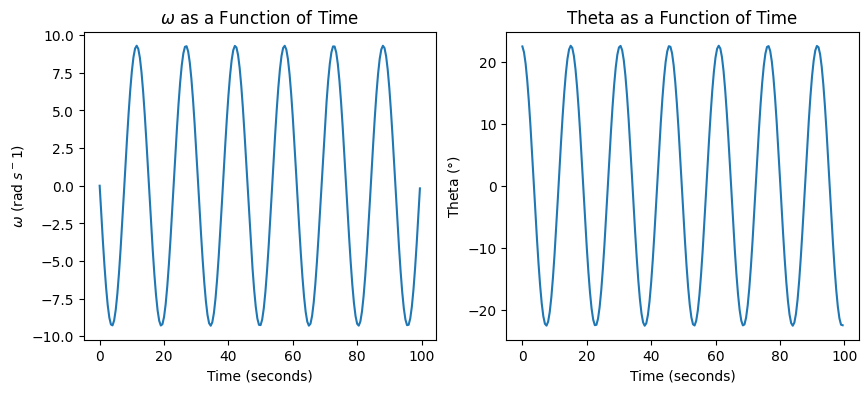

Figure 2: A plot of frequency as a function of time alongside a plot of theta as a function of time


In [2]:
# Define the timestepsize to be used in this function
TIMESTEPSIZE = 0.5
t = np.arange(0, 100, TIMESTEPSIZE) # generate some time values using the timestepsize

# Define the frequency difference equation as a function
def stepw(wi, g, l, angle, timestep = TIMESTEPSIZE):
    return wi - (g/l)*np.sin(np.deg2rad(angle))*timestep # this uses the current value of theta

# Define the angle difference equation as a function
def stepth(thi, wi, g, l, angle, timestep = TIMESTEPSIZE):
    return thi+stepw(wi, g, l, angle, TIMESTEPSIZE)*timestep # this calls the frequency timestep equation, in order to ensure that
    # w_i+1 is being used to calclate theta_i

# Pick some arbitrary values for the calculation
g = 9.8 
l = 1
w0 = 0
th0 = 22.5

# Define a function which will calculate w and theta at the same time
def w_th_vals1(w0, th0, g, l, times, timestep):
    # Initialise the arrays containing the initial conditions
    w = np.array([w0]) 
    th1 = np.array([th0])
    for x in range(1, len(times)): # Repeat for each value of time
        wi = stepw(w0, g, l, th0, TIMESTEPSIZE) # Call the function to calculate the current value of w_i
        thi = stepth(th0, w0, g, l, th0, TIMESTEPSIZE) # Call the function to calculate the current value of theta_i, using the current value of w_i
        w = np.append(w, wi) # Add the calculated values to their respective arrays
        th1 = np.append(th1, thi)
        w0 = wi # Set the current value of w_i to the one that has just been calculated
        th0 = thi # Set the current value of theta_i to the one that has just been calculated
    return [w, th1]

w, th = w_th_vals1(w0, th0, g, l, t,TIMESTEPSIZE)

# Plot omega and theta as a function of time
plt.figure(figsize = (10,4))
plt.subplot(1,2,1)
plt.title(f"$\omega$ as a Function of Time")
plt.plot(t, w)
plt.ylabel(f"$\omega$ (rad $s^{-1}$)")
plt.xlabel("Time (seconds)")
plt.subplot(1,2,2)
plt.title(f"Theta as a Function of Time")
plt.plot(t, th)
plt.ylabel(f"Theta ($\degree$)")
plt.xlabel(f"Time (seconds)")
plt.show()
print("Figure 2: A plot of frequency as a function of time alongside a plot of theta as a function of time")

As can be seen in Figure 2, both plots depict a constant sinusiodal function - which is exactly what would be expected from these equations. The intial angle was set to be $\frac{\pi}{8}$, so that the small angle approximation can be applied and so that the equations represent pendulum behaviour. 

Now that the functions have been plotted, we change the approach slightly. Instead of updating $\theta$ with the new value of $\omega$, it is updated with the old value of $\omega$. This can be seen below:

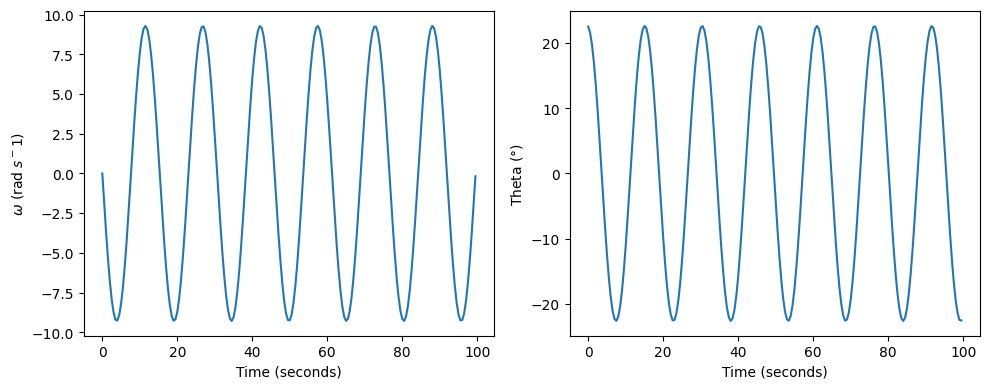

Figure 3: A plot of frequency as a function of time alongside a plot of theta as a function of time, with theta calculated using OLD values of w_i.


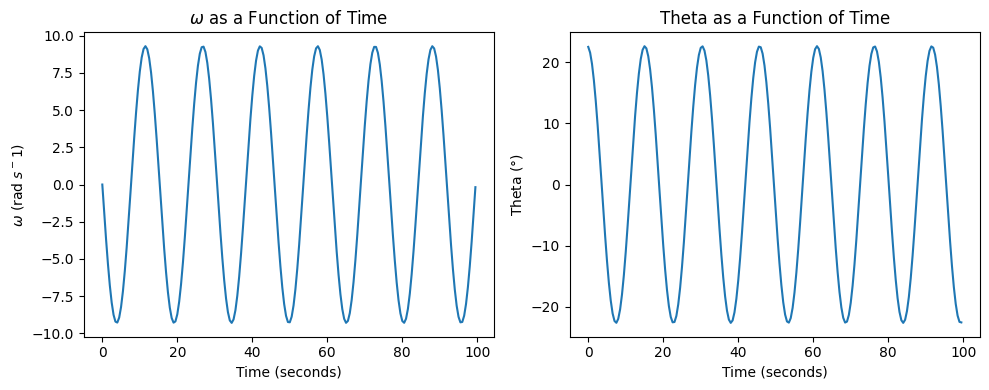

Figure 4: A plot of frequency as a function of time alongside a plot of theta as a function of time, with theta calculated using NEW values of w_i (for comparison).


In [3]:
# Reset the initial values of w and theta
w0 = 0
th0 = 22.5

# Define the new theta function which uses the old value of omega (this will be passed into the function)
def stepth2(thi, wi, timestep = TIMESTEPSIZE):
    return thi+wi*timestep

# Define a function which will calculate w and theta at the same time
def w_th_vals2(w0, th0, g, l, times, timestep):
    w = np.array([w0])
    th1 = np.array([th0])
    for x in range(1, len(times)): # repeat for each value of time
        wi = stepw(w0, g, l, th0, TIMESTEPSIZE) # Call the function to calculate the current value of w_i
        thi = stepth2(th0, wi, TIMESTEPSIZE) # Call the function to calculate the current value of theta_i, using the old value of w
        w = np.append(w, wi)
        th1 = np.append(th1, thi)
        w0 = wi # Set the current value of w_i to the one that has just been calculated
        th0 = thi # Set the current value of theta_i to the one that has just been calculated
    return [w, th1]

w1, th2 = w_th_vals2(w0, th0, g, l, t, TIMESTEPSIZE)

# Plot omega and theta as a function of time (old value of w method)
plt.figure(figsize = (10,4))
plt.subplot(1,2,1)
plt.plot(t, w)
plt.ylabel(f"$\omega$ (rad $s^{-1}$)")
plt.xlabel("Time (seconds)")
plt.subplot(1,2,2)
plt.plot(t, th)
plt.ylabel(f"Theta ($\degree$)")
plt.xlabel(f"Time (seconds)")
plt.tight_layout()
plt.show()
print("Figure 3: A plot of frequency as a function of time alongside a plot of theta as a function of time, with theta calculated using OLD values of w_i.")

# Plot omega and theta as a function of time (new value of w method)
plt.figure(figsize = (10,4))
plt.subplot(1,2,1)
plt.title(f"$\omega$ as a Function of Time")
plt.plot(t, w1)
plt.ylabel(f"$\omega$ (rad $s^{-1}$)")
plt.xlabel("Time (seconds)")
plt.subplot(1,2,2)
plt.title(f"Theta as a Function of Time")
plt.plot(t, th2)
plt.ylabel(f"Theta ($\degree$)")
plt.xlabel(f"Time (seconds)")
plt.tight_layout()
plt.show()
print("Figure 4: A plot of frequency as a function of time alongside a plot of theta as a function of time, with theta calculated using NEW values of w_i (for comparison).")

As can be seen in Figure 3, the output is identical to the output of the previous method (seen in Figure 4). So which method is better? 

The first method (calculate $\theta$ with new values of $\omega$) is called the **symplectic Euler**, and is good because it allows the energy to oscillate around the true value without long-term drift, which suits the pendulum model (where energy is conserved). 

The second method (calculate $\theta$ using old values of $\omega$) is called the **explicit Euler**, and is good because it is simple and fast, but is much less stable than the symplectic Euler. For the pendulum, it typically shows a gradual energy drift, which does not suit pendulum dynamics. It is good for small steps and short periods of time (hency why it produces a near identical result to the symplectic Euler method), but is unreliable over longer periods of time.

So overall, it can be said that the symplectic Euler method is much more reliable and better suited to pendulum dynamics.

Continuing with method 1, we now investiagate the solutions produced by the code when the initial conditions are varied.

First, the initial angle and starting angular velocity were increased from $\frac{\pi}{8}$ (conditions for small angle) and 0 respectively. The results can be seen below:

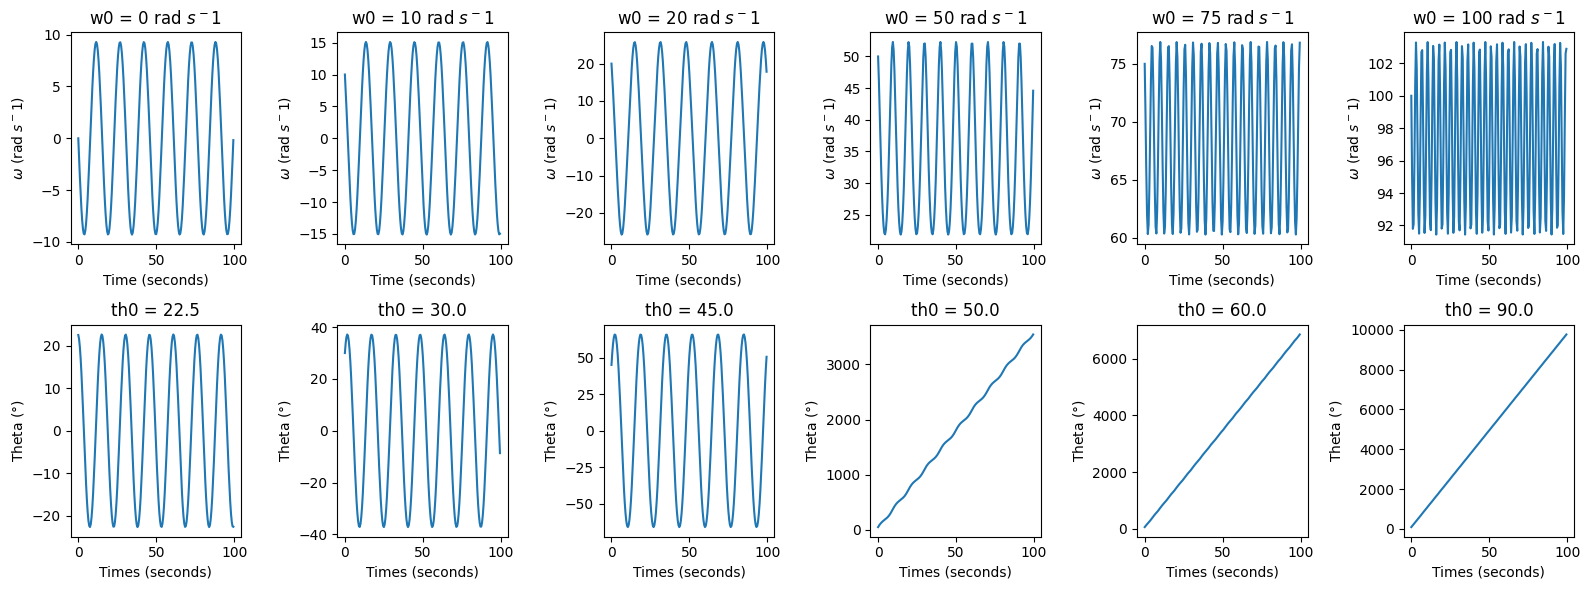

Figure 5: The variation of w and theta when varying the intial starting conditions.


In [4]:
# Define an array containing the initial starting conditions
w0s = np.array([0, 10, 20, 50, 75, 100])
th0s = np.array([22.5, 30, 45, 50, 60, 90])

# Define the figure size
plt.figure(figsize=(16,6))

# Loop through each different starting condition and plot the relevant graph
for x in range(len(w0s)):
    w, th = w_th_vals1(w0s[x], th0s[x], g, l, t, TIMESTEPSIZE) # Call the function of the symplectic Euler
    plt.subplot(2, len(w0s), x+1)
    plt.plot(t, w) # Plot the omega time graph for the current IC
    plt.title(f"w0 = {w0s[x]} rad $s^{-1}$")
    plt.xlabel("Time (seconds)")
    plt.ylabel(f"$\omega$ (rad $s^{-1}$)")
    plt.subplot(2, len(w0s), x+7)
    plt.plot(t, th) # Plot the theta time graph for the current IC
    plt.title(f"th0 = {th0s[x]}")
    plt.xlabel("Times (seconds)")
    plt.ylabel(f"Theta ($\degree$)")
    plt.tight_layout()
plt.show()
print("Figure 5: The variation of w and theta when varying the intial starting conditions.")

As can be seen in Figure 5, both $\omega$ and $\theta$ behave fairly regularly.

For low $\omega_0$, the motion is oscillatory (as expected with pendulum motion), however as $\omega_0$ increases (ie at $50 rads^{-1}$), the angular velocity becomes strictly positive, indicating that the pendulum is rotating continuously in one direction, rather than oscillating back and forth. This tells us that the initial angular velocity indicates whether the motion of the pendulum will be oscillatory or rotational.

For small angles, the motion is sinusoidal - which can be expected from small angle oscillations. At larger angles (ie 50$\degree$), the plots show monotonic growth in $\theta$ - the  pendulum goes over the top and rotates rather than oscillating. The steady linear increas in $\theta$ indicates nearly constant angular velocity, which is consistent with passing the energy threshold where oscillations turn into continuous rotation.

It can also be seen in Figure 5 that none of the plots demonstrate spiralling or unphysical growth, and the energy is not exactly conserved but appears to oscillate rather than drift (particularly in the case of higher $w_0$, where the amplitude of each oscillation is less consistent). This indicates that the symplectic Euler method was the better choice of algorithm.

The size of timestep will now be varied between 0.1, 1, 10, to see the effect of this (the initial $\omega_0$ and $\theta_0$ are set to the small amplitude oscillation conditions). This is done in the cell below:

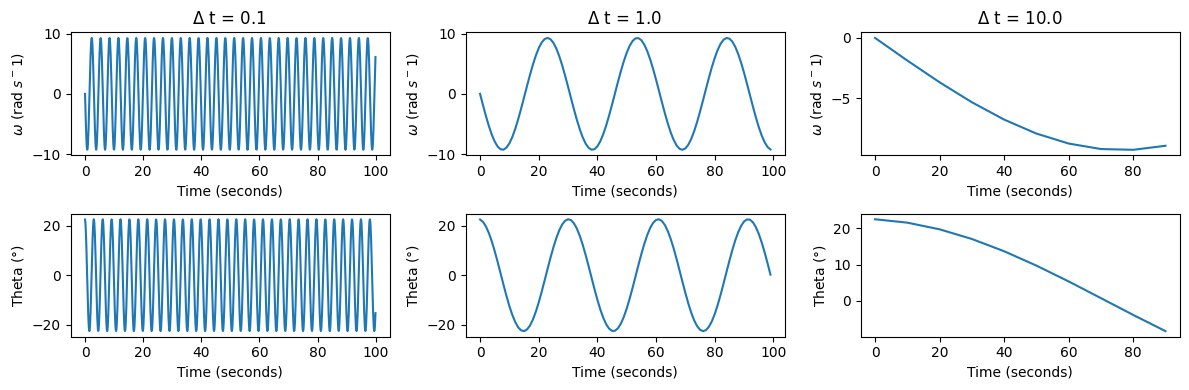

Figure 6: The effect on both plots of increasing the timestep size.


In [5]:
# Define the array containing the different timesteps and initial conditions to be used
timestepsize = np.array([0.1, 1, 10])
w0 = 0
th0 = 22.5

# Define the figure size
plt.figure(figsize=(12,4))

# Loop through each different timestep value
for x in range(len(timestepsize)):
    t = np.arange(0, 100, timestepsize[x]) # Generate the time values using the timestepsize
    w, th = w_th_vals1(w0, th0, g, l, t,timestepsize[x]) # Call the function for the current timestep size
    plt.subplot(2, len(timestepsize) , x+1) # Plot the omega time graph for the current timestep size
    plt.plot(t, w)
    plt.title(f"$\Delta$ t = {timestepsize[x]} ")
    plt.xlabel("Time (seconds)")
    plt.ylabel(f"$\omega$ (rad $s^{-1}$)")
    plt.subplot(2, len(timestepsize), x+4) # Plot the theta time graph for the current timestep size
    plt.plot(t, th)
    plt.xlabel("Time (seconds)")
    plt.ylabel(f"Theta ($\degree$)")
    plt.tight_layout()
plt.show()
print("Figure 6: The effect on both plots of increasing the timestep size.")

As can be seen in Figure 6, increasing the time step size causes the numerical solver to become unstable, and makes it difficult to get a full image of the solution (as seen when $\Delta t = 10$). On the other hand, a step size which is too small causes problems to arise due to the floating point accuracy in the computer, ie adding smaller numbers to a bigger one makes no change to the bigger number. This doesn't affect this exercise too much because the orders of magnitude are manageable by Python, however can cause issues if the programmer is not careful.

Returning to a smaller step-size (ie 0.01), the size of the starting angle will be increased from $\frac{\pi}{4}$, because a pendulum can use a rigid bar instead of a string, so can start at angle of $\frac{\pi}{2}$, however going above $\frac{\pi}{2}$ is rather pointless, because this would put the bob above the horizontal level of the pivot, whihc is impractical. The plots can be seen in the cell below:

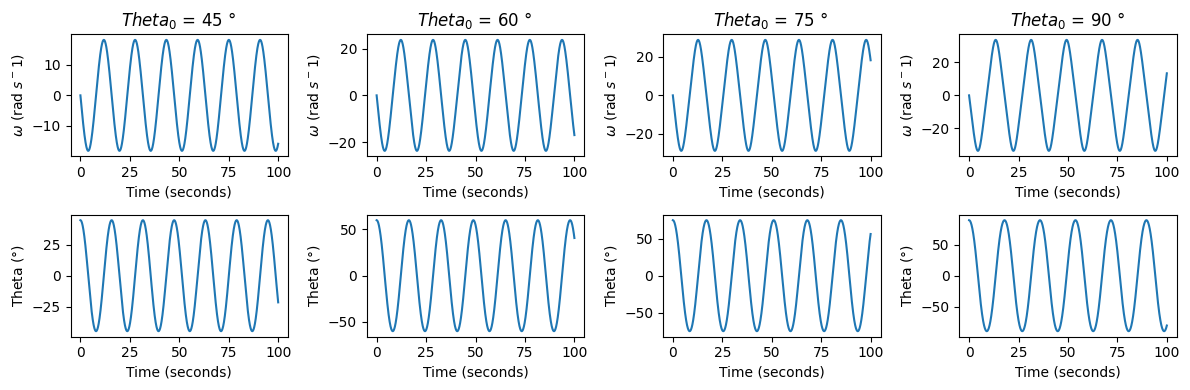

Figure 7: The effect of increasing the intial angle above 45 degrees.


In [6]:
# Define the new timestepsize and time arrays, as well as the different angle values to be used 
# (w0 remains unchanged)
TIMESTEPSIZE = 0.01
t = np.arange(0, 100, TIMESTEPSIZE)
th0s = np.array([45, 60, 75, 90])

# Define the figure size
plt.figure(figsize=(12,4))

# Loop through each different initial angle value
for x in range(len(th0s)):
    w, th = w_th_vals1(w0, th0s[x], g, l, t, TIMESTEPSIZE) # Call the function for the current initial angle value
    plt.subplot(2, len(th0s) , x+1) # Plot the omega time graph for the current angle
    plt.plot(t, w)
    plt.title(f"$Theta_0$ = {th0s[x]} $\degree$ ")
    plt.xlabel("Time (seconds)")
    plt.ylabel(f"$\omega$ (rad $s^{-1}$)")
    plt.subplot(2, len(th0s), x+5) # Plot the theta time graph for the current IC
    plt.plot(t, th)
    plt.xlabel("Time (seconds)")
    plt.ylabel(f"Theta ($\degree$)")
    plt.tight_layout()
plt.show()
print("Figure 7: The effect of increasing the intial angle above 45 degrees.")

As can be seen in Figure 7, for a simple harmonic oscillator, increasing the starting angle simply scales the amplitude of the oscillation and decreases the frequency of the oscillation.

## Part 2: Better Solvers

In this task, we make use of the built in integration solver in Python, namely the `solve_ivp` function in the `scipy.integrate` module. This takes in a function (in this case, the differential equations), the start and finish times and the initial conditons, and solves it based on the Runge-Kutta 4th order solver. We also give it one optional 'keyword' argument max_step, otherwise it will work out the largest step size it can get away with and still get a reasonable solution.

The code below uses this function to solve the differential equations we have been working with, and plots it along with the numerical method we have been using thus far, in order to compare the results obtained:

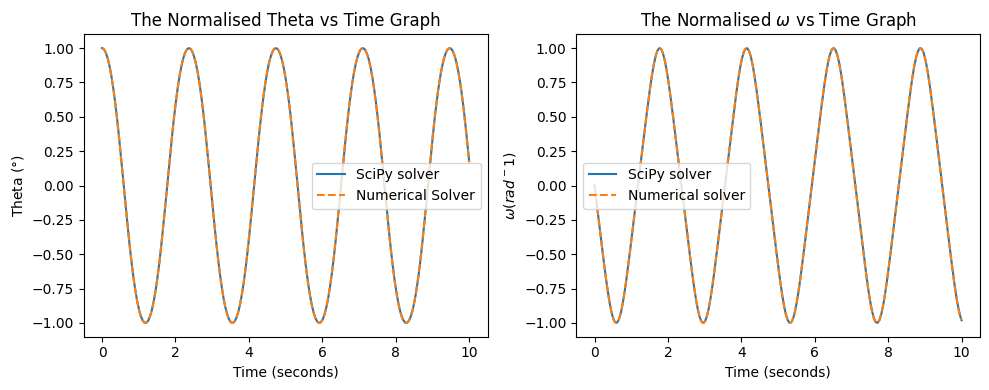

Figure 8: A side by side comparison of the SciPy library solver to the funciton that has been used throughout this exercise so far.


In [7]:
# Define the function to be used by the IVP solver
def part2_pend_ode(t, coords):
    "Function defining the pendulum ODE.  Signature as specified in scipy.integrate"
    Q, W = coords #< tuple unpacking.  
    # Here I use Q and W as theta and omega, respectively.  
    # Single-letter variable names are fine in small functions, but be more careful if you have big blocks (>10 lines) of code
    
    g = 9.81
    l = 1
    
    dQ_dt = W
    dW_dt = -g/l * np.sin(Q)
    return [dQ_dt,dW_dt]

# Define the integration conditions to be passed into the solver
TIME_RANGE = [0,10]
THETA_START = np.pi/2
OMEGA_START = 0

# Apply the solver to the function
soln = solve_ivp(part2_pend_ode, TIME_RANGE, [THETA_START, OMEGA_START], max_step = 0.05)

# Sort the solutions into the appropriate arrays
soln_times =soln.t
soln_theta, soln_omega = soln.y

#Normalise the solution
soln_theta /= np.max(soln_theta)
soln_omega /= np.max(soln_omega)

# Obtain results using the function we have been working with (timestep size obtained through trial and error)
t = np.arange(0, 10, 0.00132)
w, th = w_th_vals1(0, 90, g, l, t, 0.000132)
w /= np.max(w) # Normalise
th /= np.max(th)

# Plot the results side by side to compare
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(soln_times, soln_theta, label = "SciPy solver")
plt.plot(t, th, "--", label = "Numerical Solver")
plt.xlabel("Time (seconds)")
plt.ylabel(f"Theta ($\degree$)")
plt.title("The Normalised Theta vs Time Graph")
plt.legend()
plt.subplot(1,2,2)
plt.plot(soln_times, soln_omega, label = "SciPy solver")
plt.plot(t, w, "--", label = "Numerical solver")
plt.title(f"The Normalised $\omega$ vs Time Graph")
plt.xlabel("Time (seconds)")
plt.ylabel(f"$\omega (rad^{-1})$")
plt.legend()
plt.tight_layout()
plt.show()
print("Figure 8: A side by side comparison of the SciPy library solver to the funciton that has been used throughout this exercise so far.")

As can be seen in Figure 8, the SciPy library solver produces an identical solution to the function that has been used thus far in the exercise. This agreement indicates that the numerical solver was implemented correctly and that both solvers are converging to the same physical solution.

## Part 3 - Bungee Jumping

In the final part of the exercise, we model a bungee jump. The following forces will be acting on the jumper:

- Gravity ($mg$)
- The elastic force from the cord ($E$)
- Air resistance/drag force ($D$ - a function of jumper velocity $v$)

This gives the following equation of motion:
$$ m \vec{a} = m\vec{g} + \vec{E} + \vec{D}$$

Using a co-ordinate system where $y$ is upward and we ignore the horizontal motion of the jumper, we obtain the following differential equation:

$$\ddot{y} = g + \frac{E(y)}{m} + \frac{D(\dot{y})}{m}$$

Where $g$ (gravitational acceleration) is constant $-9.8ms^{-2}$ (downward direction). 

The drag force depends on the speed of the jumper, and acts in the opposite directin of this speed, but contains two components: the laminar drag (proportional to the velocity) and the turbulent drag (proportional to velocity squared). Therefore $D(\dot{y})$ is given by:

$$ D(\dot{y}) = -c_l \dot{y} - c_t |\dot{y}|\dot{y}$$

It is important to note that we use $|\dot{y}|\dot{y}$ and not $\dot{y}^2$, because the drag must always oppose the direction of motion - $\dot{y}^2$ is always positive and would point in the wrong direction half the time. It should also be noted that as this is a hypothetical situation, $c_l$ and $c_t$ are set to $1$.

The elastic force obeys Hookes law ($E= -kx$, where $x$ is the extension beyond the natural length $L$). The cord had a natural length of $L = 30$ and the height of the platform from which the jumper jumps is $y_0 = 80m$.

We make use of the same `solve_ivp` function used in the previous sections in order to solve the bungee ODE. The weight of the jumper is assumed to be $80kg$, and a few different the spring constant values in order $10$ are tried. This is done in the code below:

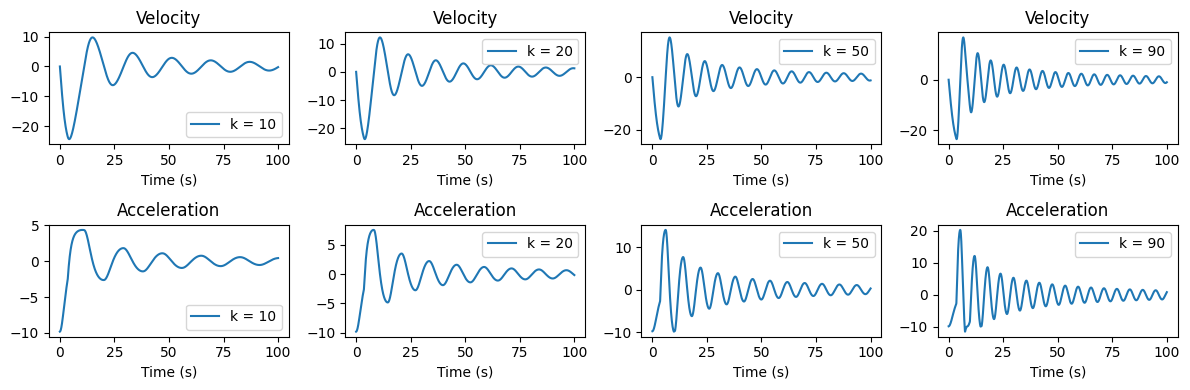

Figure 9: The effect of increasing k on the velocity and acceleration graphs.


In [8]:
# Define the function which will obtain the elastic force ie Hookes law
def hooke(k, y):
    # If y is measured upward then the cord is stretched when y < 30m
    if y<30:
        return -k*(y-30)
    else:
        return 0

# Define the function which will obtain the drag force
def D(v):
    return v*(-1-abs(v))

# Define the differential equation which will be solved by the solve_ivp
def diff(t, coords, m, g, k):
    y, v = coords # Unpack the velocity
    a = g + hooke(k, y)/m + D(v)/m # Compute the acceleration using the previously defined functions
    return [v, a] # Return the postion and acceleration

# Define the time range, intial conditons and constants
TIME_RANGE = [0,100]
dy0 = 0
y0 = 80
g = -9.81
k = np.array([10, 20, 50, 90]) # Define the different k values to be tried
m = 80

plt.figure(figsize = (12,4))
for x in range(len(k)):
    # Call the solve_ivp function to obtain solutions
    soln = solve_ivp(diff, TIME_RANGE, [y0, dy0], args=(m, g, k[x]), max_step = 0.05)
    
    # Assign the solution to the appropriate variables
    times =soln.t
    y, v = soln.y # soln.y contains the postions and velocites sampled over time

    # We need to differentiate the velocties over t in order to obtain the acceleration
    a = np.gradient(v, times)

    # Plot the velocity and acceleration graphs
    #plt.figure(figsize = (12,4))
    plt.subplot(2, len(k), x+1)
    plt.plot(times, v, label = f"k = {k[x]}")
    plt.xlabel("Time (s)")
    plt.legend()
    plt.title(f"Velocity")
    plt.subplot(2, len(k), x+5)
    plt.plot(times, a, label = f"k = {k[x]}")
    plt.xlabel("Time (s)")
    plt.legend()
    plt.title(f"Acceleration")
    plt.tight_layout()
plt.show()

print("Figure 9: The effect of increasing k on the velocity and acceleration graphs.")

As can be seen Figure 8, increasing the spring constant causes the oscillations in both velocity and acceleration to become noticeably faster. This is expected because a larger $k$ corresponds to a stiffer bungee cord, which produces a stronger restoring force once the cord is stretched. The initial part of the motion is identical for all $k$, since the jumper is in free fall until the cord becomes taut. After the cord engages, higher $k$ values result in quicker reversals of motion, more rapid oscillations, and larger peak accelerations immediately following the first extension.

It should also be noted that the acceleration graphs appear to form a straight line initially, before assuming the expected sinusoidal pattern. This is due to the initial freefall of the jumper before the bungee cord engages - the gravitational acceleration is the only acceleration acting until the bungee cord becomes extended, and the elastic and drag forces begin to act.

We now investigate the effects of increasing the initial velocity and starting positon of the jumper (imagnining that the jumper can jump from higher than the platform). This is done in the code below:

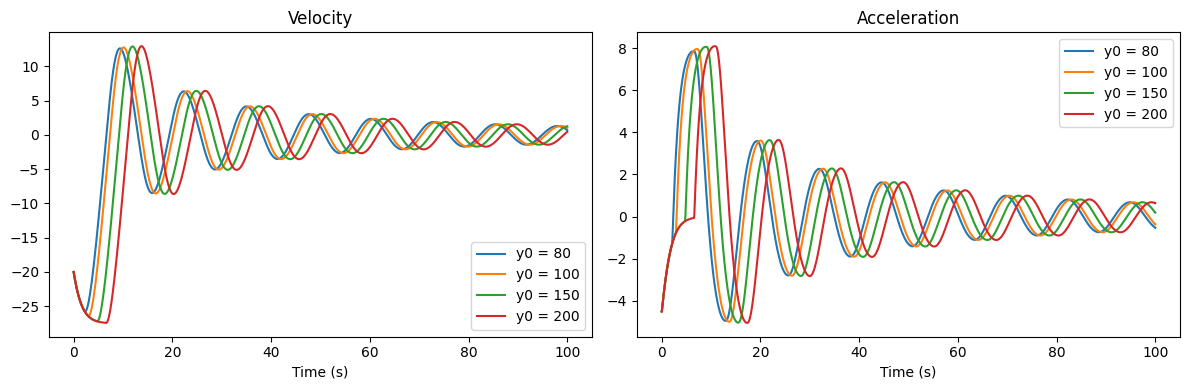

Figure 10: The effect of increasing the initial height from which the jumper jumps on the velocity and acceleration graphs.


In [9]:
# Define the different inital conditons to be tested
dy0 = np.array([-20, -10, 0, 10, 20])
y0 = np.array([80, 100, 150, 200])

plt.figure(figsize = (12,4))
for x in range(len(y0)):
    soln = solve_ivp(diff, TIME_RANGE, [y0[x], dy0[0]], args=(m, g, k[1]), max_step = 0.05)
    times =soln.t
    y, v = soln.y
    a = np.gradient(v, times)
    plt.subplot(1, 2, 1)
    plt.plot(times, v, label = f"y0 = {y0[x]}")
    plt.legend()
    plt.title(f"Velocity")
    plt.xlabel("Time (s)")
    plt.subplot(1, 2, 2)
    plt.plot(times, a, label = f"y0 = {y0[x]}")
    plt.xlabel("Time (s)")
    plt.legend()
    plt.title(f"Acceleration")
    plt.tight_layout()
plt.show()

print("Figure 10: The effect of increasing the initial height from which the jumper jumps on the velocity and acceleration graphs.")

As can be seen in Figure 10, increasing the $y_0$ increases the intial peak values of both velocity and acceleration, but the general oscillation behaviour remains relatively unchanged.

It should also be noted that the initial portion of the acceleration graph which forms a straight line increases with increasing $y_0$. This is because increasing $y_0$ delays the engagement of the cord, causing a slight horizontal shift in the graph and yielding a larger peak velocity and a longer time where gravity is the only force acting. 

We now look at the effect of increasing the initial velocity:

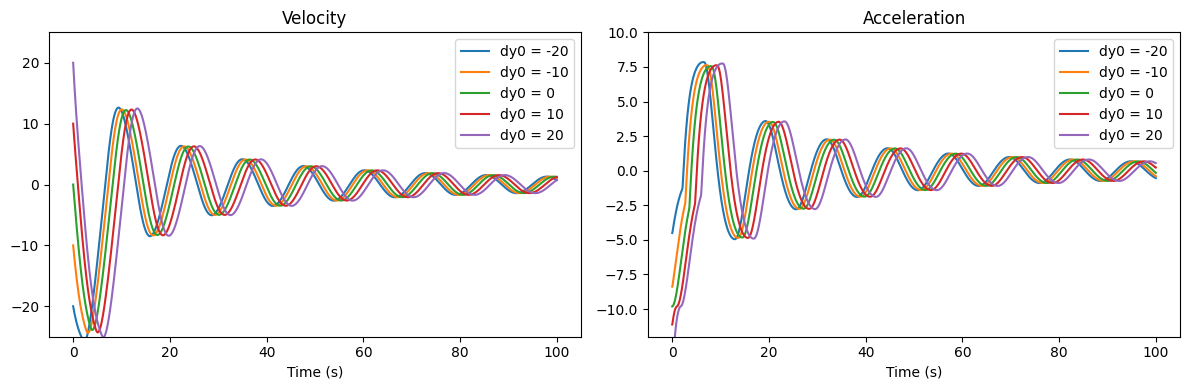

Figure 11: The effect of increasing the initial velocity of the jumper on the velocity and acceleration graphs.


In [10]:
plt.figure(figsize = (12,4))
for x in range(len(dy0)):
    soln = solve_ivp(diff, TIME_RANGE, [y0[0], dy0[x]], args=(m, g, k[1]), max_step = 0.05)
    times =soln.t
    y, v = soln.y
    a = np.gradient(v, times)
    plt.subplot(1, 2, 1)
    plt.plot(times, v, label = f"dy0 = {dy0[x]}")
    plt.ylim(-25, 25)
    plt.legend()
    plt.title(f"Velocity")
    plt.xlabel("Time (s)")
    plt.subplot(1, 2, 2)
    plt.plot(times, a, label = f"dy0 = {dy0[x]}")
    plt.ylim(-12, 10)
    plt.legend()
    plt.title(f"Acceleration")
    plt.xlabel("Time (s)")
    plt.tight_layout()
plt.show()

print("Figure 11: The effect of increasing the initial velocity of the jumper on the velocity and acceleration graphs.")

As can be seen in Figure 11, changing the initial velocity primarily affects the starting point of the velocity and acceleration graphs - larger initial velocities (both positive and negative), produce slightly larger early oscillations, but the effects of the elastic and drag forces reduces this effect pretty quickly.

In order to ensure safety of the jumper, it should be ensured that the height of the jumper above the ground is always greater than the maximum extension of the cord - otherwise the jumper hits the ground. When this happens, all motion ceases, and the velocity and acceleration graphs flatline. 

The acceleration of the jumper is initially $g$ when the jumper is in freefall, then when the cord is engaged, the elastic and drag forces begin to act, making the acceleration $\ddot{y} = g + \frac{E(y)}{m} + \frac{D(\dot{y})}{m}$ (our ODE). The motion is eventually damped over time, and the jumper eventually comes to rest and the oscillations tend to 0.

We finally check if the k values tested were also suitable for the $60kg$ and $100kg$ jumpers. A $k$ value of $50$ is used, as this appeared to produce the smoothest velocity and accelartion graphs - indicating a gentler acceleration (see Figure 9). This is done in the code below:

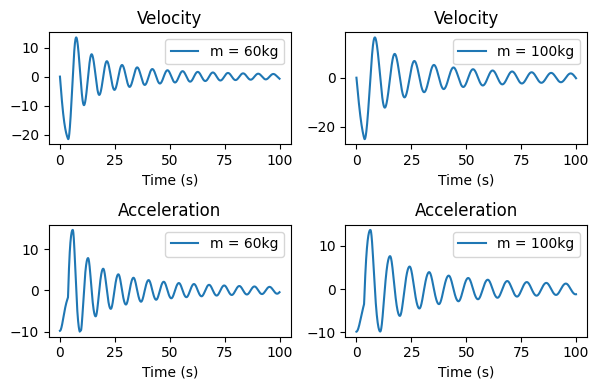

Figure 12: The velocity and acceleration graphs of the 60kg and 100kg jumpers.


In [11]:
plt.figure(figsize = (12,4))
m = np.array([60, 100])
for x in range(len(m)):
    # Call the solve_ivp function to obtain solutions
    soln = solve_ivp(diff, TIME_RANGE, [y0[0], dy0[2]], args=(m[x], g, k[2]), max_step = 0.05)
    
    # Assign the solution to the appropriate variables
    times =soln.t
    y, v = soln.y # soln.y contains the postions and velocites sampled over time

    # We need to differentiate the velocties over t in order to obtain the acceleration
    a = np.gradient(v, times)

    # Plot the velocity and acceleration graphs
    #plt.figure(figsize = (12,4))
    plt.subplot(2, len(k), x+1)
    plt.plot(times, v, label = f"m = {m[x]}kg")
    plt.legend()
    plt.title(f"Velocity")
    plt.xlabel("Time (s)")
    plt.subplot(2, len(k), x+5)
    plt.plot(times, a, label = f"m = {m[x]}kg")
    plt.legend()
    plt.title(f"Acceleration")
    plt.xlabel("Time (s)")
    plt.tight_layout()
plt.show()

print("Figure 12: The velocity and acceleration graphs of the 60kg and 100kg jumpers.")

As seen in Figure 12, the graphs behave exactly as expected - indicating that a $k$ value of $50$ is a suitable choice, and works for the $60kg$ and $100kg$ jumpers.

## Conclusion

Overall, this exercise has successfully achieved its aims. Part 1 investiagted the pendulum ODEs, and established functions to solve it numerically - both the symplectic and implicit Euler methods were used, but it was determined that the symplectic Euler method was more stable in the long-term. The behaviour of the solutions were investigated, with changing timestep, starting angled and initial velocities, and it was found that the solutions behaved as expected.

Part 2 saw the introduction of the `solve_ivp` function from `scipy.integrate`, and this was used to solve the pendulum equations and compare these solutions to the numerical method used in part 1. It was found that the solutions produced were identical, indicating that the numerical solver was implmemented correctly.

Part 3 then investigated a bungee jump model, and used the techniques from the pendulum equations to solve the bungee ODEs (equations of motion). The `solve_ivp` function was used to obtain velocity and acceleration graphs, and these solutions were investigated by using different values of $k$, $y_0$, $v_0$ and $m$.